<b><font size="6" color="#E8800A">Homework · Group 44 · Part 1 — Import and explore the data</font></b><br>
<b><font size="4">Everything & Then Some, Ltd. · Predicting a repeat purchase within 90 days</font></b><br>

**Machine Learning 2026/2027 · NOVA IMS** · Kaggle team `ML_Group_44`

This notebook covers point 1 of the brief: *inspect `train.csv` and, if useful, `clientes.csv`; describe the
observations and variables; provide descriptive statistics; check data quality and inconsistencies; and explore
univariate and multivariate relationships.*

**Nothing in this notebook changes the data that the model will see.** Here we only *diagnose*. Every problem we
find is recorded with a planned fix, and the fixes are applied in Part 2 inside a reproducible pipeline that is fitted on
training rows only. `test.csv` is opened only to compare it with `train.csv` (dates, customers, category levels),
never to compute a statistic used in modelling.

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>1 · The business need</font>](#business)
* [<font color='#E8800A'>2 · Setup</font>](#setup)
* [<font color='#E8800A'>3 · Import the data</font>](#import)
* [<font color='#E8800A'>4 · Structural survey: what is each column?</font>](#survey)
* [<font color='#E8800A'>5 · The target and the floor</font>](#target)
* [<font color='#E8800A'>6 · Data quality</font>](#quality)
* [<font color='#E8800A'>7 · Train vs test: the test set is the future</font>](#drift)
* [<font color='#E8800A'>8 · Univariate analysis</font>](#univariate)
* [<font color='#E8800A'>9 · Relationships with the target</font>](#bivariate)
* [<font color='#E8800A'>10 · Redundancy between predictors</font>](#redundancy)
* [<font color='#E8800A'>11 · The customer table `clientes.csv`</font>](#clientes)
* [<font color='#E8800A'>12 · Identifiers and the noise column</font>](#identifiers)
* [<font color='#E8800A'>13 · Key findings and decisions carried to Part 2</font>](#findings)

</div>

# <font color='#E8800A'>1 · The business need</font> <a class="anchor" id="business"></a>
[Back to TOC](#toc)

Everything & Then Some supplies businesses and specialist retailers (tools, lighting, automotive care, household
goods). The company wants to know **which customers are likely to come back soon after a purchase**, so it can plan
targeted commercial actions.

Following the five objects of a supervised problem (Week 1):

| Object | In this problem |
|---|---|
| **Observation** | one *purchase occasion* (one row of `train.csv`) |
| **Target** | `repeat_purchase_90d`: 1 if the same customer buys again within the next 90 days, 0 otherwise |
| **Features** | what is known **at the moment of that purchase**: the invoice itself, the customer's purchase history before it, the commercial context, and (optionally) the customer's master data |
| **Prediction moment** | right after the purchase is recorded. Nothing that happens after it may be used |
| **Decision** | whether to include the customer in a commercial action (e.g. a follow-up offer) |

The prediction moment matters for leakage: every history column in the file is named `prior_*` or describes a window
that *ends* at the purchase (`spend_30d`, `purchase_count_90d`, ...), so they are legitimate. We check this assumption
in Section 6.

**How the work is graded on Kaggle:** the competition metric is the **F1-score of class 1** computed on hard 0/1
predictions. This shapes the whole analysis, starting with the floor in Section 5.

# <font color='#E8800A'>2 · Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

The usual stack: `pandas`/`numpy` for data, `matplotlib`/`seaborn` for plots, `joblib` to save fitted objects later,
and `scipy.stats` for the association measures used in class (point-biserial correlation, chi-square and Cramér's V).

The paths are built with `os.path.join`, so the notebook runs on Windows, macOS and Linux alike. We also name the three
columns with a **special structural role** once, here, and refer to them by these names everywhere:

* `target_col`: what we predict;
* `group_col`: the customer key. It links purchases of the same customer and joins `clientes.csv`; it is not a feature;
* `index_col`: the row identifier. It becomes the index and is kept unchanged for the submission file.

In [2]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import joblib
import seaborn as sns

# Extra tools used in this notebook (statistical tests seen in class)
import warnings
from scipy import stats
from scipy.stats import chi2_contingency

train_path=os.path.join("..","data","raw","train.csv")
test_path=os.path.join("..","data","raw","test.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

#Variables with special structural roles
target_col = "repeat_purchase_90d"
group_col = "customer_id"
index_col = "ID"

# Notebook settings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_STATE = 44                                  # our group number, used as seed everywhere
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"      # course plot colours
FIGSIZE = (10, 4.5)

# <font color='#E8800A'>3 · Import the data</font> <a class="anchor" id="import"></a>
[Back to TOC](#toc)

Three files. `ID` identifies a row (a purchase occasion), so it goes straight into the index: that way it can never be
handed to a model by accident, and it stays untouched for the submission file.

> **Note:** we pass `index_col=index_col` (i.e. `"ID"`) and not `index_col=0`. The first column of `train.csv` is
> `Total a Pagar`, so `index_col=0` would silently turn the amount paid into the index and remove it from the
> features, while `ID` would stay as an ordinary column.

In [3]:
df_raw = pd.read_csv(train_path, index_col=index_col, sep=",")
df_test = pd.read_csv(test_path, index_col=index_col, sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

for name, frame in [("train", df_raw), ("test", df_test), ("clientes", df_clientes)]:
    print(f"{name:9s} {frame.shape[0]:>6,} rows x {frame.shape[1]:>2} columns")

train      6,534 rows x 38 columns
test         986 rows x 37 columns
clientes   1,143 rows x 13 columns


In [4]:
df_raw.head(10)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.00,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.300000,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.00,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.680000,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.00,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.800000,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.00,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.330000,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.00,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.500000,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890
10000005,640.78,568.24,520.96,119.82,0.00,0.0,47.28,336.600650,11.0,1.0,1,21.0,1589.0,17.0,28706.97,1688.645294,1225.468600,22.58,3938.48,98.000000,85.819190,1.0,3938.48,1.0,3938.48,2.0,7624.15,2.0,7624.150000,821421,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 62,Final Excel Warehouse 1,Ctrl Z Series 2,2023-07-15,-0.011464
10000007,122.83,105.55,100.43,22.40,3.05,0.0,5.12,0.000000,5.0,1.0,1,2.0,182.0,9.0,7472.49,830.276667,1349.820379,24.11,3882.36,22.500000,19.892569,3.0,601.08,5.0,4638.16,8.0,7327.82,9.0,NaN,974136,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 53,Final Excel Warehouse 1,Ctrl Z Series 3,2016-12-02,-0.747859
10000009,1409.75,1272.44,1146.14,263.61,0.00,0.0,126.30,246.974108,66.0,1.0,1,7.0,1469.0,42.0,66306.16,1578.718095,1519.092817,140.07,6991.26,35.658537,32.598780,1.0,1023.69,2.0,1626.35,6.0,5457.27,11.0,11854.190000,488020,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 1,2021-03-27,-0.716275
10000011,962.63,786.27,782.63,180.00,0.00,0.0,3.64,496.926279,46.0,1.0,0,223.0,742.0,8.0,12487.24,1560.905000,1035.729065,130.18,3356.83,74.142857,57.831446,0.0,0.00,0.0,0.00,0.0,0.00,3.0,53906.674517,796571,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,-0.519772


In [5]:
# info() shows how each column was read and how many values are present.
df_raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

**First observations**

* `train.csv` has **6,534 purchase occasions** and 38 columns besides the index; `test.csv` has the same columns minus the target.
* All the money and count columns were read as numbers, the 7 text columns as strings, and `purchase_date` as text
  (it will need to be parsed).
* Many columns have exactly **6,469 non-null values** → the same 65 rows seem to be empty in all of them (Section 6.1).
* Several history columns (`prior_*`, `days_since_previous_purchase`) have far fewer values → structural missingness (Section 6.3).

# <font color='#E8800A'>4 · Structural survey: what is each column?</font> <a class="anchor" id="survey"></a>
[Back to TOC](#toc)

To better organize our data we chose to group the variables by themes. Every later section refers to these groups,
which makes the material easier to find, and the rest of the notebook treats each group consistently: nothing is
treated that was not named here.

In [6]:
#Variables with special structural roles are defined in the setup: target_col, group_col, index_col

# Grouping by themes
var_groups = {
    "Identifier": [
        "ID",
        "customer_id"
    ],
    "Target": [
        "repeat_purchase_90d"
    ],
    "Current transaction (financial)": [
        "Total a Pagar",
        "Total Bruto",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Custo"
    ],
    "Current transaction (operational)": [
        "N_ Detalhes",
        "invoice_count_current_purchase"
    ],
    "Transaction context & date": [
        "purchase_date",
        "payment_type",
        "salesperson",
        "commercial_zone",
        "warehouse",
        "document_series",
        "transport_method"
    ],
    "Customer historical summary": [
        "customer_tenure_days",
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ],
    "Customer cadence & gaps": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "prior_std_gap_days"
    ],
    "Rolling windows (RFM)": [
        "purchase_count_30d",
        "spend_30d",
        "purchase_count_90d",
        "spend_90d",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ],
    "Synthetic / Control": [
        "random_noise"
    ]
}

# Sanity check: every column of the file (index included) is in exactly one group
listed = [c for cols in var_groups.values() for c in cols]
assert sorted(listed) == sorted([index_col] + list(df_raw.columns)), "a column is missing from var_groups"

# Column lists used in the rest of the notebook, built from the groups
date_col = "purchase_date"
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])
categorical_cols = [c for c in var_groups["Transaction context & date"] if c != date_col]

pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()], columns=["Group", "# vars", "Variables"])

,Group,# vars,Variables
0,Identifier,2,"ID, customer_id"
1,Target,1,repeat_purchase_90d
2,Current transaction (financial),8,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
3,Current transaction (operational),2,"N_ Detalhes, invoice_count_current_purchase"
4,Transaction context & date,7,"purchase_date, payment_type, salesperson, comm..."
5,Customer historical summary,7,"customer_tenure_days, prior_purchase_count, pr..."
6,Customer cadence & gaps,3,"days_since_previous_purchase, prior_mean_gap_d..."
7,Rolling windows (RFM),8,"purchase_count_30d, spend_30d, purchase_count_..."
8,Synthetic / Control,1,random_noise


* **Identifier** and **Target** hold the three structural roles defined in the setup.
* The current transaction is split in two: the **financial** amounts of the invoice and its **operational** size
  (number of lines and of invoices).
* The customer's past is split by what it measures: **historical summary** (how long, how many, how much),
  **cadence & gaps** (how often and how recently) and **rolling windows** (recent frequency and monetary value, the
  F and M of RFM).
* `random_noise` gets its own **Synthetic / Control** group: we do not trust it, but we keep it as a control (Section 12).

The column lists used in the rest of the notebook (`numeric_cols`, `categorical_cols`) are built from these groups, so
there is a single source of truth.

We then apply the identifier rule from Week 3: *a column that is distinct on more than half of its rows identifies
the row rather than describing it.*

In [7]:
# Columns that are (almost) unique per row behave like identifiers, whatever their dtype.
distinct_share = (df_raw.reset_index().nunique() / len(df_raw)).sort_values(ascending=False)
distinct_share.head(6).round(3).to_frame("share of distinct values")

,share of distinct values
ID,1.000
random_noise,0.990
Total a Pagar,0.937
Total Liquido,0.933
Total Bruto,0.924
prior_total_spend,0.897


`ID` is unique per row, as expected. `random_noise` is also almost unique per row, but it is a continuous
number, so the rule alone does not settle it. Its name is suspicious and we test it in Section 12.
`customer_id` is **not** unique: 610 customers for 6,534 purchases (Section 6.2).

In [8]:
# A dtype is how a value is stored, not what it measures: numeric columns with few distinct
# values could be codes written as numbers.
low_card = {c: df_raw[c].nunique() for c in numeric_cols if df_raw[c].nunique() <= 10}
print("numeric columns with <= 10 distinct values:", low_card)
print("\nlevels per categorical column:")
print(df_raw[categorical_cols].nunique().sort_values(ascending=False).to_string())

numeric columns with <= 10 distinct values: {'invoice_count_current_purchase': 5}

levels per categorical column:
transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2


* The only low-cardinality numeric column is `invoice_count_current_purchase` (1 to 5 invoices in the same
  purchase occasion). It is a genuine count, not a code, so it stays numeric.
* The categoricals go from 2 levels (`warehouse`) to **80 levels** (`transport_method`). The labels are anonymised
  ("Maybe Tomorrow Payment 10", "VLOOKUP Master 9", ...), so they carry no domain meaning we could exploit by hand;
  their value can only be measured against the target (Section 9.3).

# <font color='#E8800A'>5 · The target and the floor</font> <a class="anchor" id="target"></a>
[Back to TOC](#toc)

Look at the target before looking at anything against it. **A score means nothing on its own**: it must be read
against what a model that does no work would get (Week 1).

In [9]:
balance = df_raw[target_col].value_counts().sort_index()
print(balance.to_frame("rows").assign(share=lambda f: (f["rows"] / f["rows"].sum()).round(3)).to_string())

# The two floors: always predict the majority class (accuracy), and always predict 1 (F1 of class 1).
p = df_raw[target_col].mean()
print(f"\nalways predict 1 -> accuracy {p:.3f} | F1(class 1) {2 * p / (1 + p):.3f}")
print(f"always predict 0 -> accuracy {1 - p:.3f} | F1(class 1) 0.000")

                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

always predict 1 -> accuracy 0.559 | F1(class 1) 0.717
always predict 0 -> accuracy 0.441 | F1(class 1) 0.000


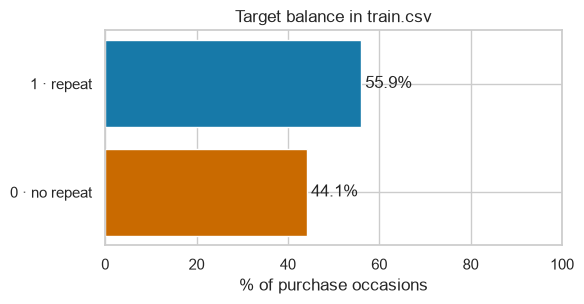

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.2))
shares = df_raw[target_col].value_counts(normalize=True).sort_index() * 100
ax.barh(["0 · no repeat", "1 · repeat"], shares.values, color=[PLOT_ORANGE, PLOT_BLUE])
for i, v in enumerate(shares.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set(xlim=(0, 100), xlabel="% of purchase occasions", title="Target balance in train.csv")
plt.tight_layout()
plt.show()

**What this tells us**

* The classes are **mildly imbalanced, and class 1 is the majority** (≈56%). That is unusual: in most screening
  problems the positive class is rare.
* Because the competition scores the **F1 of class 1**, the trivial model "everybody comes back" already scores
  **F1 ≈ 0.72**. F1 ignores true negatives, so predicting 1 is cheap and missing a 1 is expensive.
* Two consequences for later: (1) every F1 we report will be compared with the all-ones floor, and
  (2) the decision **threshold** is part of the model. The default 0.5 is not necessarily the one that maximises F1.
* Resampling (SMOTE, undersampling) is not needed: the minority class still has ≈2,900 rows.

# <font color='#E8800A'>6 · Data quality</font> <a class="anchor" id="quality"></a>
[Back to TOC](#toc)

We first **diagnose** and only later fix, so we know exactly what each fix does and how many rows it touches.

### 6.1 Rows with no information

In [11]:
# How many values does each row carry, ignoring the identifiers and the target?
info_cols = [c for c in df_raw.columns if c not in [group_col, target_col]]
filled = df_raw[info_cols].notna().sum(axis=1)
print(filled.value_counts().sort_index().tail(8).to_string())

empty_rows = filled == 0
print(f"\nrows with ZERO informative values: {empty_rows.sum()} "
      f"({100 * empty_rows.mean():.2f}% of df_raw), repeat rate {df_raw.loc[empty_rows, target_col].mean():.2f}")
print("same problem in test.csv:", int((df_test[info_cols].notna().sum(axis=1) == 0).sum()), "rows")

28      86
29     511
31       6
32     100
33     354
34     190
35    1287
36    3929

rows with ZERO informative values: 65 (0.99% of df_raw), repeat rate 0.51
same problem in test.csv: 0 rows


**65 rows (1%) carry nothing but `customer_id` and the target.** No invoice, no history, no date, no category. They
look like failed extractions. (They are also the reason a naive `duplicated()` on the raw file reports 10 duplicate rows:
empty rows of the same customer look identical.) No imputation can recover a row that has no measured value, and `test.csv` has no
such rows, so learning from them would teach the model nothing it will ever use.
→ **Planned fix:** drop these 65 training rows.

### 6.2 Duplicates and repeated customers

Three questions (Week 3): exact copies, repeated identifiers, and repeated entities.

In [12]:
# df = the working copy of train without the 65 empty rows (df_raw stays untouched for comparison)
df = df_raw.loc[~empty_rows]

print("exact duplicate rows (ignoring ID):", df.duplicated().sum())
print("duplicate rows ignoring ID AND target:", df.drop(columns=target_col).duplicated().sum())
print("duplicated IDs:", df_raw.index.duplicated().sum())

per_customer = df_raw.groupby(group_col).size()
print(f"\n{df_raw['customer_id'].nunique()} customers for {len(df_raw):,} purchases")
print(per_customer.describe().round(1).to_string())

exact duplicate rows (ignoring ID): 0
duplicate rows ignoring ID AND target: 0
duplicated IDs: 0

610 customers for 6,534 purchases
count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0


In [13]:
# On the RAW file, duplicated() finds copies; are they all among the empty rows?
raw_dups = df_raw.duplicated(keep=False)
print("rows involved in a duplicate on the raw file:", raw_dups.sum(),
      "| of which empty rows:", (raw_dups & empty_rows).sum())

rows involved in a duplicate on the raw file: 16 | of which empty rows: 16


* Once the empty rows are set aside there are **no duplicated purchases**: every informative row is distinct. The
  duplicates a quick check reports on the raw file are all empty rows of the same customer, already handled by 6.1.
* The more important fact is that **customers repeat**: 610 customers, median 4 purchases each, and one customer with
  **277**. Rows of the same customer are not independent, so a random split puts purchases of the same customer on
  both sides. Section 7 shows why this matters for validation.

### 6.3 Missing values

From here on we look at the rows that carry information (the 65 empty rows would otherwise dominate every count).

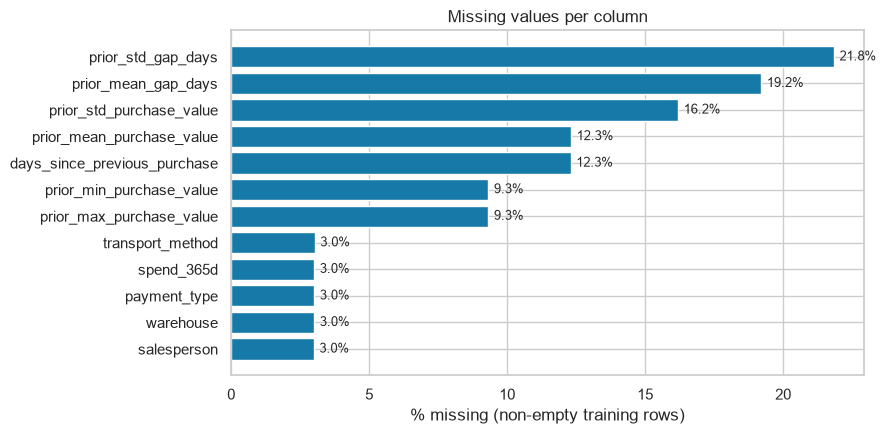

,n_missing,pct
prior_std_gap_days,1413,21.84
prior_mean_gap_days,1243,19.21
prior_std_purchase_value,1048,16.20
prior_mean_purchase_value,797,12.32
days_since_previous_purchase,796,12.30
prior_min_purchase_value,603,9.32
prior_max_purchase_value,603,9.32
transport_method,196,3.03
spend_365d,195,3.01
payment_type,195,3.01


In [14]:
missing = (df.isna().sum().to_frame("n_missing")
           .assign(pct=lambda f: 100 * f["n_missing"] / len(df))
           .query("n_missing > 0").sort_values("n_missing", ascending=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(missing.index, missing["pct"], color=PLOT_BLUE)
for i, v in enumerate(missing["pct"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="% missing (non-empty training rows)", title="Missing values per column")
plt.tight_layout()
plt.show()
missing.round(2)

Two different patterns appear:

1. **History columns** (`prior_*_gap_days`, `prior_std_purchase_value`, `days_since_previous_purchase`, ...): 12–22% missing.
   These could be *structural*: a customer with no previous purchase has no gap and no "days since previous purchase".
2. **Commercial context** (`payment_type`, `salesperson`, `transport_method`, `warehouse`) and `spend_365d`: ≈3% each.

We test both hypotheses instead of assuming them.

In [15]:
# Hypothesis 1: history columns are missing because the customer has (almost) no history.
history_missing = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                   "prior_min_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = df["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
table = (df[history_missing].isna()
         .groupby(prior_n).mean().mul(100).round(1)
         .assign(rows=prior_n.value_counts()))
table.index.name = "prior purchases"
table

,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_mean_gap_days,prior_std_gap_days,rows
prior purchases,,,,,,,
0,100.0,100.0,100.0,100.0,100.0,100.0,603
1,4.3,4.5,100.0,0.0,100.0,100.0,445
2,5.5,3.0,0.0,0.0,5.8,100.0,365
3+,3.0,3.2,0.0,0.0,3.4,0.0,5056


The hypothesis holds **only in part**:

* With **0 prior purchases**, every history column is missing in 100% of rows, as expected: there is no history.
* With **1 prior purchase**, the gap and the standard deviations are always missing (one purchase has no gap and no
  spread), but `days_since_previous_purchase` should exist, and it is still missing for a fraction of rows.
* With **2 or more** prior purchases, all these columns *should* exist, yet a few percent are missing anyway. That
  part is ordinary missingness, not structural.

So "missing = no history" (the business-logic reading, MNAR) explains most but not all of it. This decides the fix: we
add an explicit flag such as `is_first_purchase` (`prior_purchase_count == 0`) and *missing indicators*, then impute
the remaining gaps with the **training median**. We do **not** fill gaps with 0: a gap of 0 days would mean "buys every
day", which is the opposite of "no history".

In [16]:
# Hypothesis 2: are the context gaps random? Check overlap between columns and the target rate.
context_missing = ["payment_type", "salesperson", "transport_method", "warehouse", "spend_365d"]
flags = df[context_missing].isna()
print("rows missing in k of these 5 columns:", flags.sum(axis=1).value_counts().sort_index().to_dict())

rates = pd.DataFrame({
    "rows missing": flags.sum(),
    "repeat rate when missing": [df.loc[flags[c], target_col].mean() for c in context_missing],
    "repeat rate when present": [df.loc[~flags[c], target_col].mean() for c in context_missing],
}).round(3)
rates

rows missing in k of these 5 columns: {0: 5544, 1: 875, 2: 50}


,rows missing,repeat rate when missing,repeat rate when present
payment_type,195,0.564,0.560
salesperson,194,0.598,0.559
transport_method,196,0.551,0.560
warehouse,195,0.636,0.557
spend_365d,195,0.564,0.560


In [17]:
# Is missingness associated with any categorical feature? (chi-square + Cramer's V, Week 3)
def cramers_v(x, y):
    """Chi-square df_test on a contingency table and Cramer's V as effect size (0 = none, 1 = perfect)."""
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan, np.nan
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return v, p_value


rows = []
for flag_col in context_missing:
    for col in [c for c in categorical_cols if c != flag_col]:
        v, p_value = cramers_v(flags[flag_col], df[col].fillna("<missing>"))
        rows.append({"missing in": flag_col, "vs": col, "Cramer's V": v, "p": p_value})
assoc = pd.DataFrame(rows).pivot(index="missing in", columns="vs", values="Cramer's V").round(3)
assoc

vs,commercial_zone,document_series,payment_type,salesperson,transport_method,warehouse
missing in,,,,,,
payment_type,0.071,0.012,NaN,0.035,0.083,0.008
salesperson,0.005,0.026,0.026,NaN,0.101,0.012
spend_365d,0.005,0.015,0.039,0.023,0.104,0.010
transport_method,0.010,0.025,0.035,0.021,NaN,0.006
warehouse,0.005,0.021,0.051,0.024,0.140,NaN


* The context gaps **almost never overlap** (no row misses more than two of these columns), and the repeat rate is
  practically the same with and without the value. The one visible gap (`warehouse`: 0.64 vs 0.56) rests on 195 rows,
  about two standard errors, so it is weak evidence.
* Missingness has at most a **weak** association with the other categoricals (Cramér's V ≤ 0.14). The largest values
  all involve `transport_method`, whose 80 levels inflate V on their own.
* Overall this is consistent with values **missing (close to) completely at random (MCAR)**.
* → **Planned fix:** categorical gaps become their own level `"Missing"` (cheap, and honest about the gap);
  `spend_365d` gaps are imputed with the training median (after the cleaning in 6.4).

### 6.4 Impossible values

`describe()` is the quickest way to spot values that the domain forbids.

In [18]:
df[numeric_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

,min,25%,50%,75%,max
Total a Pagar,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,0.00,0.00,13.13,92.28,4.103440e+03
Custo,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,1.00,1.00,1.00,1.00,5.000000e+00


Three things cannot be true:

* `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** (one billion euros), while their medians are
  ≈725 € and ≈2,400 €.
* `days_since_previous_purchase` and `prior_mean_gap_days` have **negative** values (a gap cannot be negative), and
  `prior_mean_purchase_value` and `spend_365d` too (spending cannot be negative).

Random damage would scatter over many values. Placeholders sit on a few exact values, so we look at the values themselves.

In [52]:
checks = {
    "prior_mean_purchase_value": df["prior_mean_purchase_value"],
    "spend_365d": df["spend_365d"],
    "days_since_previous_purchase": df["days_since_previous_purchase"],
    "prior_mean_gap_days": df["prior_mean_gap_days"],
}
for name, s in checks.items():
    bad = s[(s < 0) | (s >= 1e8)]
    print(f"{name:30s} {len(bad):3d} impossible values -> {bad.value_counts().head(4).to_dict()}")

prior_mean_purchase_value       32 impossible values -> {1000000000.0: 16, -110.14709677419351: 1, -409.7916666666667: 1, -218.2663917525773: 1}
spend_365d                      30 impossible values -> {1000000000.0: 15, -3456.32: 1, -1230.72: 1, -167.18: 1}
days_since_previous_purchase    16 impossible values -> {-4.0: 16}
prior_mean_gap_days             16 impossible values -> {-4.0: 16}


In [20]:
# Do the sentinels sit on the same rows? And does the same happen in test.csv?
def sentinel_mask(frame):
    return pd.DataFrame({
        "billion": (frame["prior_mean_purchase_value"] >= 1e8) | (frame["spend_365d"] >= 1e8),
        "negative": (frame["days_since_previous_purchase"] < 0) | (frame["prior_mean_gap_days"] < 0)
                    | (frame["prior_mean_purchase_value"] < 0) | (frame["spend_365d"] < 0),
    })


s_train, s_test = sentinel_mask(df), sentinel_mask(df_test)
print(pd.crosstab(s_train["billion"], s_train["negative"]).rename_axis(index="billion", columns="negative"))
print(f"\ntrain: {s_train.any(axis=1).sum()} rows with a sentinel | test: {s_test.any(axis=1).sum()} rows")
print("repeat rate on sentinel rows:", round(df.loc[s_train.any(axis=1), target_col].mean(), 3))

negative  False  True 
billion               
False      6375     63
True         31      0

train: 94 rows with a sentinel | test: 12 rows
repeat rate on sentinel rows: 0.532


* There are **two problems, on different rows**: the value **1e9** (31 rows, in `prior_mean_purchase_value` and
  `spend_365d`) and **negative values** (63 rows): exactly −4 days in the two gap columns, and assorted negative
  amounts in the two money columns. In total 94 training rows (1.5%) carry at least one impossible cell.
* 1e9 and −4 are exact repeated values, so they are codes written by the source system. The negative amounts vary,
  so they look more like calculation errors (e.g. refunds netted into an average). Either way the value is unusable.
  The other columns of those rows look normal, and their repeat rate (0.53) is close to the average, so only the
  cell is wrong, not the whole row.
* `test.csv` contains the same patterns, so the fix must be a **rule** applied identically to both files, not a row deletion.
* → **Planned fix:** turn these cells into `NaN` (the value is unknown, not zero) and let the training-median imputation fill them.
  This is the "blank the cell" treatment that won in Week 3.

### 6.5 Internal consistency

Several columns are linked by definition. If the links hold, we can trust the columns (and we learn that some of
them are **redundant by construction**).

In [21]:
def share_true(condition):
    return f"{100 * condition.mean():.1f}%"

d = df
consistency = {
    "Bruto - Desc_Linha - Desc_Global = Liquido": share_true(
        (d["Total Bruto"] - d["Total Desc_ Linha"] - d["Total Desc_ Global"] - d["Total Liquido"]).abs() < 1),
    "Liquido + Imp_ + Portes = a Pagar": share_true(
        (d["Total Liquido"] + d["Total Imp_"] + d["Total Portes"] - d["Total a Pagar"]).abs() < 1),
    "count_30d <= count_90d <= count_180d <= count_365d": share_true(
        (d["purchase_count_30d"] <= d["purchase_count_90d"]) & (d["purchase_count_90d"] <= d["purchase_count_180d"])
        & (d["purchase_count_180d"] <= d["purchase_count_365d"])),
    "spend_30d <= spend_90d <= spend_180d": share_true(
        (d["spend_30d"] <= d["spend_90d"] + 0.01) & (d["spend_90d"] <= d["spend_180d"] + 0.01)),
    "purchase_count_365d <= prior_purchase_count": share_true(d["purchase_count_365d"] <= d["prior_purchase_count"]),
    "prior_min <= prior_max (when both exist)": share_true(
        (d["prior_min_purchase_value"] <= d["prior_max_purchase_value"])[d["prior_max_purchase_value"].notna()]),
    "days_since_previous <= tenure (when both exist)": share_true(
        (d["days_since_previous_purchase"] <= d["customer_tenure_days"])[d["days_since_previous_purchase"].notna()]),
    "Custo <= Total Liquido (no sale below cost)": share_true(d["Custo"] <= d["Total Liquido"]),
}
pd.Series(consistency).to_frame("rows where it holds")

,rows where it holds
Bruto - Desc_Linha - Desc_Global = Liquido,100.0%
Liquido + Imp_ + Portes = a Pagar,83.7%
count_30d <= count_90d <= count_180d <= count_365d,100.0%
spend_30d <= spend_90d <= spend_180d,100.0%
purchase_count_365d <= prior_purchase_count,100.0%
prior_min <= prior_max (when both exist),100.0%
days_since_previous <= tenure (when both exist),100.0%
Custo <= Total Liquido (no sale below cost),99.4%


* The **money identities hold**: net = gross − discounts in 100% of rows, and paid = net + tax + shipping in 84%. In the
  other 16% the difference is a few euros (median ≈5 €) and the amount paid is exactly 1.23 × net, i.e. the standard
  Portuguese VAT rate; the small gap is tax not recorded in `Total Imp_`. Plausible, not an error.
* So `Total a Pagar`, `Total Bruto` and `Total Liquido` are three views of the same amount → redundancy to handle in
  feature selection (Section 10).
* The **rolling windows are perfectly nested** (30d ≤ 90d ≤ 180d ≤ 365d) and never exceed the full history. This
  confirms that they describe the period *before* the purchase, so they are legitimate features (no leakage).
* Sales below cost are rare (<1%), which is plausible (promotions) rather than an error.

### 6.6 Categorical levels

In [22]:
level_rows = []
for col in categorical_cols:
    counts = df[col].value_counts()
    unseen = set(df_test[col].dropna()) - set(df[col].dropna())
    level_rows.append({
        "levels (df_raw)": counts.size,
        "levels (df_test)": df_test[col].nunique(),
        "levels with < 1% of rows": int((counts / len(df) < 0.01).sum()),
        "largest level share": round(counts.iloc[0] / counts.sum(), 3),
        "test levels never seen in train": len(unseen),
        "test rows with an unseen level": int(df_test[col].isin(unseen).sum()),
    })
pd.DataFrame(level_rows, index=categorical_cols)

,levels (df_raw),levels (df_test),levels with < 1% of rows,largest level share,test levels never seen in train,test rows with an unseen level
payment_type,9,11,5,0.728,3,3
salesperson,9,3,4,0.646,0,0
commercial_zone,5,5,3,0.968,2,209
warehouse,2,2,1,0.997,1,7
document_series,3,1,0,0.423,0,0
transport_method,80,29,59,0.178,2,63


* No spelling variants: each level is written consistently, so no label cleaning is needed.
* **Many rare levels**, especially in `transport_method` (most of its 80 levels have under 1% of the rows). One-hot
  encoding them all would create dozens of almost-empty columns. → **Planned fix:** group levels below a minimum
  frequency into `"Other"` (`OneHotEncoder(min_frequency=...)`).
* `test.csv` contains **levels never seen in train** (in `payment_type`, `commercial_zone`, `transport_method` and
  `warehouse`). This is not marginal: **209 test rows (21%) have a `commercial_zone` that does not exist in train**.
  The encoder must not fail on them → `handle_unknown="infrequent_if_exist"`, which sends them to the same "Other" column.
  For those rows the model can learn nothing from the zone.
* `commercial_zone` (97% in one zone) and `warehouse` (99.7%) are almost constant in train.
* `document_series` is the opposite case: 3 balanced levels in train, but **a single level in test**. Whatever the model
  learned about the other two series is never used.

### 6.7 Summary of data quality issues

| Issue | Rows affected (train) | Also in test? | Planned fix (Part 2) |
|---|---|---|---|
| Rows with no information | 65 (1.0%) | no | drop from training |
| 1e9 placeholders | 31 | yes | → `NaN`, then median imputation |
| Negative impossible values (−4 days, negative spend) | 63 | yes | → `NaN`, then median imputation |
| Structural missing history (no previous purchase) | ≈600–1,500 per column | yes | `is_first_purchase` flag + missing indicators + training median |
| Context columns MCAR (≈3% each) | ≈195 per column | yes | categorical → `"Missing"` level; `spend_365d` → training median |
| Rare categorical levels | most of `transport_method` | yes | group into `"Other"` (`min_frequency`) |
| Levels unseen in train | — | yes | `handle_unknown="infrequent_if_exist"` |
| Repeated customers (610 customers, 6,534 rows) | all | yes | consider in the validation design |

All fixes that *learn* something (medians, frequent levels) are fitted on training rows only. The two
placeholder rules and the row drops are fixed rules that learn nothing from the data.

# <font color='#E8800A'>7 · Train vs test: the test set is the future</font> <a class="anchor" id="drift"></a>
[Back to TOC](#toc)

A model is only as good as the resemblance between the rows it learns from and the rows it predicts. We compare
the two files on time, customers and feature distributions.

In [23]:
train_dates = pd.to_datetime(df["purchase_date"])
test_dates = pd.to_datetime(df_test["purchase_date"])
print(f"train: {train_dates.min():%Y-%m-%d} -> {train_dates.max():%Y-%m-%d}")
print(f"test : {test_dates.min():%Y-%m-%d} -> {test_dates.max():%Y-%m-%d}")

by_year = pd.DataFrame({"train rows": train_dates.dt.year.value_counts(),
                        "test rows": test_dates.dt.year.value_counts(),
                        "train repeat rate": df.groupby(train_dates.dt.year)[target_col].mean().round(3)})
by_year.index = by_year.index.astype(int)
by_year.sort_index().fillna(0).astype({"train rows": int, "test rows": int})

train: 2015-07-11 -> 2025-02-15
test : 2025-05-24 -> 2026-10-06


,train rows,test rows,train repeat rate
purchase_date,,,
2015,335,0,0.534
2016,420,0,0.514
2017,670,0,0.633
2018,716,0,0.538
2019,646,0,0.522
2020,670,0,0.594
2021,782,0,0.549
2022,628,0,0.481
2023,767,0,0.581


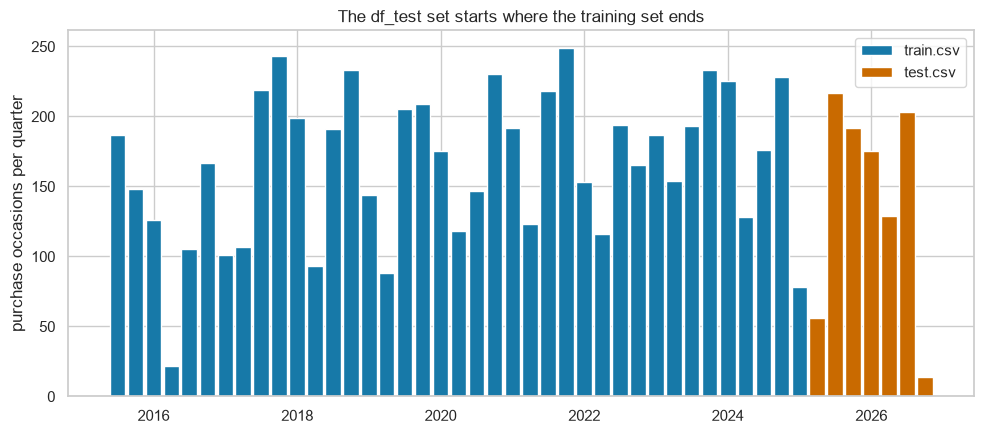

In [24]:
fig, ax = plt.subplots(figsize=FIGSIZE)
monthly_train = train_dates.dt.to_period("Q").value_counts().sort_index()
monthly_test = test_dates.dt.to_period("Q").value_counts().sort_index()
ax.bar(monthly_train.index.to_timestamp(), monthly_train.values, width=80, color=PLOT_BLUE, label="train.csv")
ax.bar(monthly_test.index.to_timestamp(), monthly_test.values, width=80, color=PLOT_ORANGE, label="test.csv")
ax.set(ylabel="purchase occasions per quarter", title="The df_test set starts where the training set ends")
ax.legend()
plt.tight_layout()
plt.show()

In [25]:
train_customers = set(df[group_col])
test_customers = set(df_test[group_col])
known = df_test[group_col].isin(train_customers)
print(f"test customers: {len(test_customers)} | already in train: {len(test_customers & train_customers)}"
      f" | new: {len(test_customers - train_customers)}")
print(f"test ROWS from known customers: {known.mean():.1%}")

test customers: 206 | already in train: 184 | new: 22
test ROWS from known customers: 94.5%


This is one of the most important findings for the whole project:

* **The test set is the future.** Training purchases run from 2015 to February 2025, and test purchases from May 2025 to
  October 2026, with no overlap in time.
* **The test customers are mostly known.** 184 of the 206 test customers already appear in train, and they account for
  **94.5% of the test rows**.
* The repeat rate **moves over time** (≈0.48 to ≈0.63 depending on the year). The recent years are above the average,
  which already hints at some *population drift* (Data Mining, S3).

**Consequence for the assessment strategy (Part 4):** the validation that best imitates Kaggle is a **temporal
split** (train on the past, validate on the most recent period), where most validation customers are also known.
A `GroupKFold` by customer, sometimes recommended because customers repeat, would simulate *new* customers, which is
not the situation of the test set. We will compare designs explicitly instead of picking one by assumption.

In [26]:
# Do the feature distributions drift? Median of key features: train (all years), train (2023+), test.
recent = train_dates >= "2023-01-01"
key = ["Total a Pagar", "N_ Detalhes", "days_since_previous_purchase", "customer_tenure_days",
       "prior_purchase_count", "prior_total_spend", "purchase_count_90d", "spend_90d", "purchase_count_365d"]
pd.DataFrame({"train (all)": df[key].median(),
              "train (2023+)": df.loc[recent, key].median(),
              "test": df_test[key].median()}).round(1)

,train (all),train (2023+),test
Total a Pagar,476.7,634.4,663.9
N_ Detalhes,11.0,15.0,15.0
days_since_previous_purchase,57.0,61.0,59.0
customer_tenure_days,918.0,2082.0,2662.0
prior_purchase_count,11.0,21.0,28.0
prior_total_spend,6754.3,15013.7,25186.5
purchase_count_90d,1.0,1.0,1.0
spend_90d,198.5,352.6,472.7
purchase_count_365d,3.0,4.0,4.0


`customer_tenure_days`, `prior_purchase_count` and `prior_total_spend` grow over time: they are cumulative, so a
customer observed in 2026 necessarily has a longer history than in 2016. The test rows therefore sit at the top of
the training distribution for these columns, and some of them beyond it. Two implications:

* features that only measure *how long ago* the customer started will be **extrapolated** on the test set, and
  absolute calendar features (such as the purchase *year*) would be even worse, because the test years do not exist in
  train. We will not use the year as a feature;
* behaviour features that do **not** drift by construction (recency, frequency in fixed windows, ratios) are the
  safest candidates, and the recent invoice values are comparable.

# <font color='#E8800A'>8 · Univariate analysis</font> <a class="anchor" id="univariate"></a>
[Back to TOC](#toc)

### 8.1 Numeric variables: shape

`.describe()` gives the centre and spread. We add the statistics it leaves out (Week 3): the mean/median ratio, the
skewness and the share of zeros. The sentinels are blanked first (only in this exploration copy), otherwise they
would dominate every statistic.

In [27]:
# Exploration copy with the placeholders blanked (the same rule Part 2 will apply).
df_eda = df.copy()
for col in ["prior_mean_purchase_value", "spend_365d"]:
    df_eda.loc[(df_eda[col] >= 1e8) | (df_eda[col] < 0), col] = np.nan
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    df_eda.loc[df_eda[col] < 0, col] = np.nan

shape = df_eda[numeric_cols].describe().T[["mean", "50%", "std", "max"]]
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = df_eda[numeric_cols].skew()
shape["% zeros"] = 100 * (df_eda[numeric_cols] == 0).mean()
shape.sort_values("skew", ascending=False).round(2)

,mean,50%,std,max,mean/median,skew,% zeros
Total Desc_ Global,0.35,0.00,5.12,218.49,NaN,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,5901.55,267526.19,1.65,21.34,0.00
prior_mean_purchase_value,957.93,724.90,1609.56,72937.16,1.32,21.20,0.00
Total Portes,1.15,0.00,5.84,181.06,NaN,19.55,83.72
spend_365d,5777.74,2426.60,13900.88,522933.21,2.38,18.55,12.52
prior_mean_gap_days,96.18,68.61,122.65,3199.00,1.40,9.31,0.00
prior_std_gap_days,74.14,50.64,101.82,2212.54,1.46,7.77,0.02
days_since_previous_purchase,101.83,57.00,165.84,3199.00,1.79,6.53,0.00
invoice_count_current_purchase,1.07,1.00,0.31,5.00,1.07,6.44,0.00
Total Desc_ Linha,112.47,13.13,289.99,4103.44,8.57,5.92,37.73


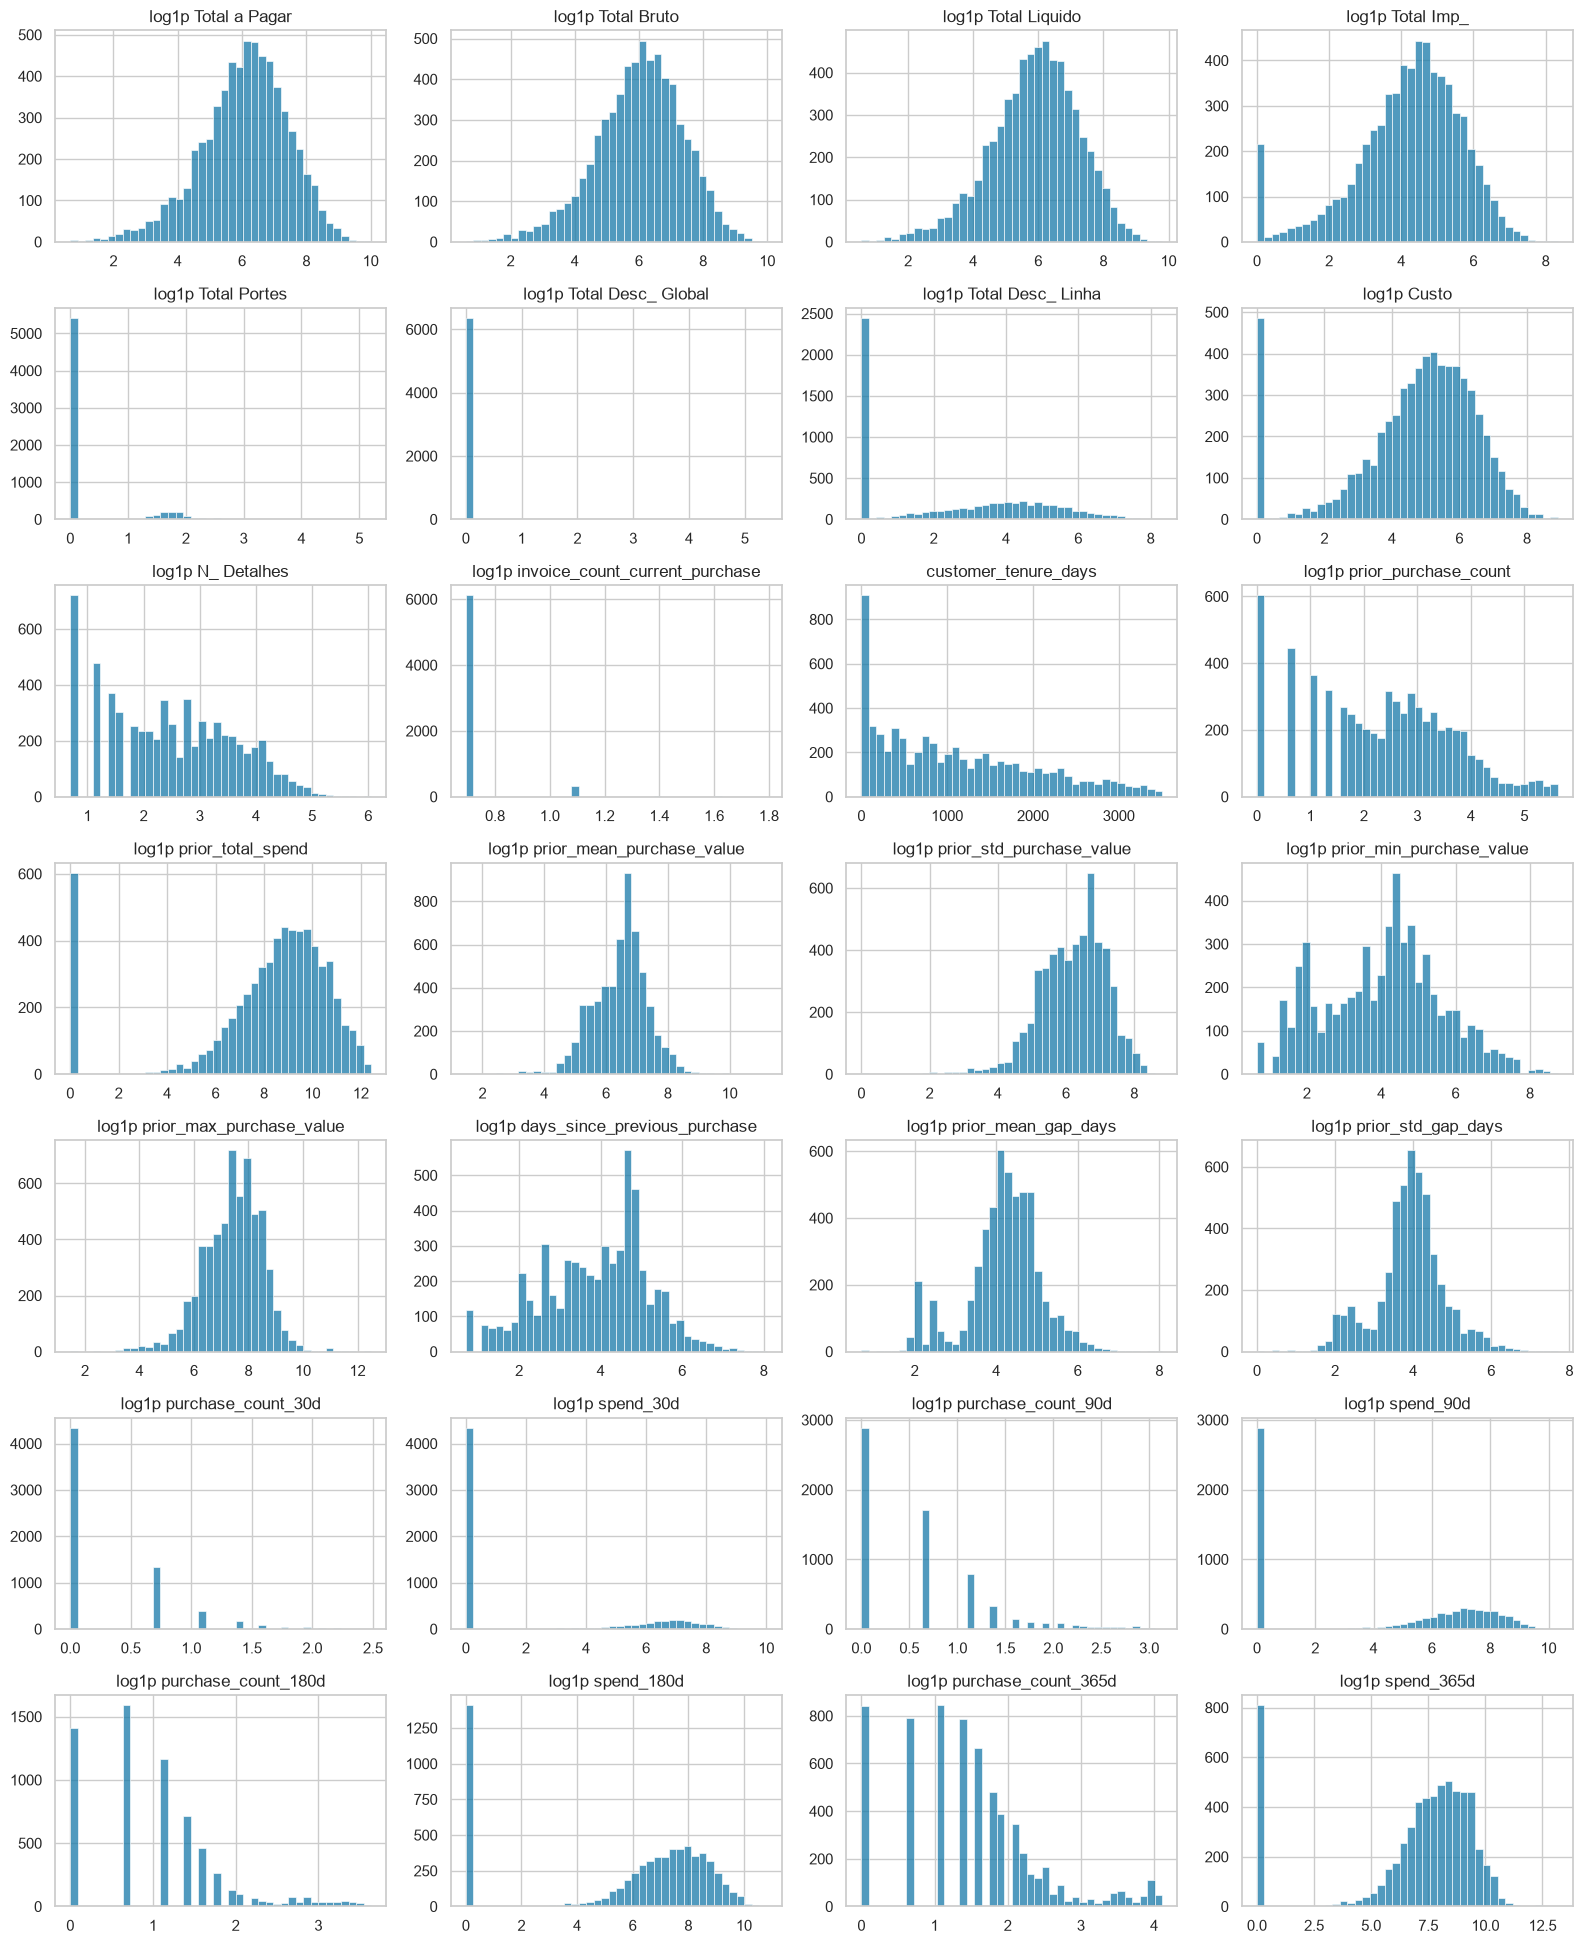

In [28]:
def plot_hist_grid(frame, cols, log_cols=(), n_per_row=4, color=PLOT_BLUE):
    """One histogram per column; columns in `log_cols` are shown as log(1 + x) so long tails are readable."""
    n_rows = int(np.ceil(len(cols) / n_per_row))
    fig, axes = plt.subplots(n_rows, n_per_row, figsize=(4 * n_per_row, 2.8 * n_rows))
    for ax, col in zip(axes.flat, cols):
        values = frame[col].dropna()
        if col in log_cols:
            values = np.log1p(values.clip(lower=0))
        sns.histplot(values, bins=40, color=color, ax=ax)
        ax.set(title=("log1p " if col in log_cols else "") + col, xlabel="", ylabel="")
    for ax in list(axes.flat)[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


skewed = shape.index[shape["skew"] > 2].tolist()
plot_hist_grid(df_eda, numeric_cols, log_cols=skewed)

**What the shapes say**

* Almost every money and count column is **strongly right-skewed** (skew > 2, mean several times the median): many
  small purchases and a long tail of very large ones. On the log scale most of them become roughly bell-shaped, which
  suggests a `log1p` transform for the models that care about scale and linearity (logistic regression).
* `Total Portes` and `Total Desc_ Global` are **zero in the vast majority of rows** (shipping and global discounts
  are rare), so they carry little information; `invoice_count_current_purchase` is almost always 1.
* The rolling-window counts have **many zeros** (most customers did not buy in the last 30 days), which is information,
  not a problem: zero means "no recent purchase".

### 8.2 Where the boxplot rule fails

In [29]:
# The 1.5 x IQR rule on a skewed column: how many rows would it call outliers, and who are they?
rows = []
for col in ["Total a Pagar", "prior_total_spend", "spend_365d", "N_ Detalhes", "prior_purchase_count"]:
    s = df_eda[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    out = s > q3 + 1.5 * (q3 - q1)
    rows.append({"column": col, "% flagged by 1.5 IQR": round(100 * out.mean(), 1),
                 "repeat rate flagged": round(df_eda.loc[out[out].index, target_col].mean(), 3),
                 "repeat rate rest": round(df_eda.loc[out[~out].index, target_col].mean(), 3)})
pd.DataFrame(rows).set_index("column")

,% flagged by 1.5 IQR,repeat rate flagged,repeat rate rest
column,,,
Total a Pagar,9.2,0.674,0.548
prior_total_spend,9.9,0.841,0.529
spend_365d,7.2,0.878,0.535
N_ Detalhes,6.7,0.635,0.554
prior_purchase_count,7.7,0.974,0.525


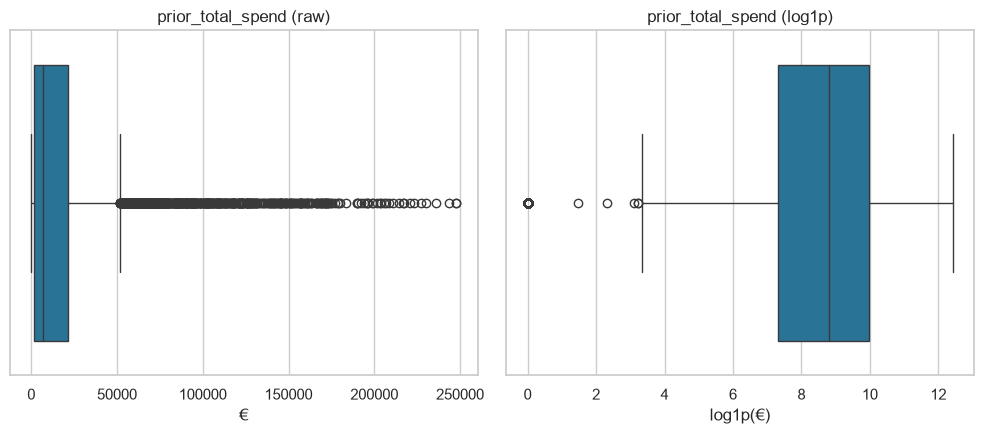

In [30]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
sns.boxplot(x=df_eda["prior_total_spend"], color=PLOT_BLUE, ax=axes[0])
axes[0].set(title="prior_total_spend (raw)", xlabel="€")
sns.boxplot(x=np.log1p(df_eda["prior_total_spend"]), color=PLOT_BLUE, ax=axes[1])
axes[1].set(title="prior_total_spend (log1p)", xlabel="log1p(€)")
plt.tight_layout()
plt.show()

* On skewed columns the 1.5 × IQR rule flags **7–10% of the rows** as "outliers".
* These are not errors: they are the **best customers**. Their repeat rate is far higher than the rest: 0.97 vs 0.53
  for `prior_purchase_count`, 0.88 vs 0.54 for `spend_365d`. Deleting
  them would remove exactly the customers the company most wants to keep and would bias the class balance (the same
  lesson as Week 3, where the IQR drop removed 67% of the data).
* On the log scale the boxplot becomes symmetric and the "outliers" mostly disappear.
* → **Planned fix:** keep every row with a legitimate value; compress the tails with `log1p` instead of cutting them.
  The only values removed are the impossible ones from 6.4.

### 8.3 Categorical variables

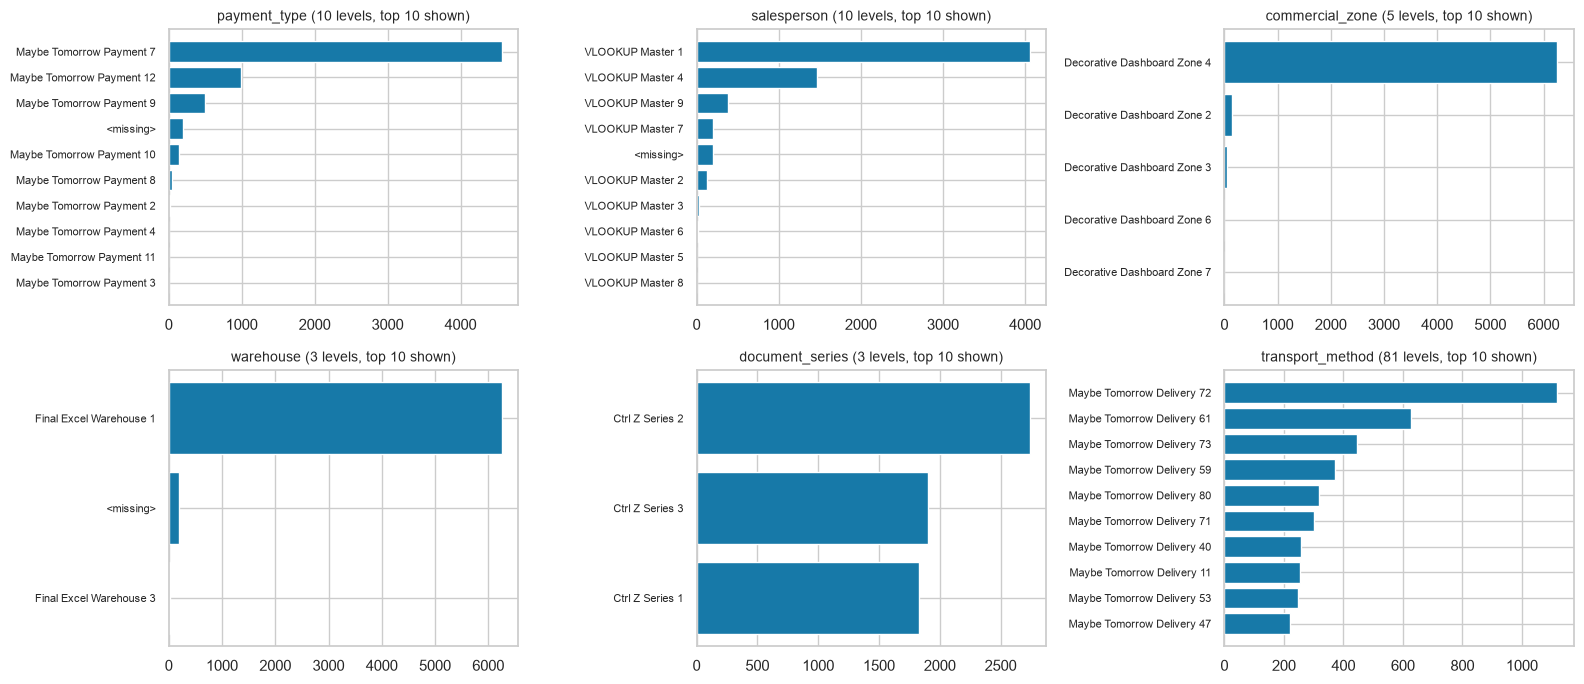

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, categorical_cols):
    counts = df_eda[col].fillna("<missing>").value_counts()
    top = counts.head(10)
    ax.barh(top.index[::-1], top.values[::-1], color=PLOT_BLUE)
    ax.set_title(f"{col} ({counts.size} levels, top 10 shown)", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `warehouse` (99.7%) and `commercial_zone` (97%) are almost constant; `salesperson` has one main level (65%);
  `document_series` is split across three series.
* `transport_method` has a long tail: a handful of methods cover most rows, and dozens appear only a few times.
* `payment_type` is more spread out, with several frequent levels.

# <font color='#E8800A'>9 · Relationships with the target</font> <a class="anchor" id="bivariate"></a>
[Back to TOC](#toc)

### 9.1 Which numeric variables separate repeaters from non-repeaters?

For a numeric variable against a binary target, the course measure is the **point-biserial correlation** (Pearson's r
with a 0/1 variable). Because the variables are skewed, we compute it on `log1p` values, and we also report the
**Spearman** correlation, which uses ranks and is robust to the tails. We also show the **median** in each class.

In [32]:
def signed_log1p(s):
    return np.sign(s) * np.log1p(np.abs(s))


rel_rows = []
for col in numeric_cols:
    pair = df_eda[[col, target_col]].dropna()
    r_pb, p_pb = stats.pointbiserialr(pair[target_col], signed_log1p(pair[col]))
    rho, _ = stats.spearmanr(pair[col], pair[target_col])
    rel_rows.append({"feature": col, "point-biserial r (log1p)": r_pb, "Spearman rho": rho, "p-value": p_pb,
                     "median | 0": pair.loc[pair[target_col] == 0, col].median(),
                     "median | 1": pair.loc[pair[target_col] == 1, col].median()})
relevance = pd.DataFrame(rel_rows).set_index("feature")
relevance = relevance.reindex(relevance["Spearman rho"].abs().sort_values(ascending=False).index)
relevance.round(3)

,point-biserial r (log1p),Spearman rho,p-value,median | 0,median | 1
feature,,,,,
purchase_count_365d,0.424,0.437,0.000,2.000,5.000
prior_mean_gap_days,-0.389,-0.420,0.000,101.750,55.758
purchase_count_180d,0.407,0.406,0.000,1.000,3.000
purchase_count_90d,0.396,0.393,0.000,0.000,1.000
spend_365d,0.308,0.388,0.000,1150.160,4544.380
spend_180d,0.317,0.370,0.000,457.870,2106.220
spend_90d,0.351,0.359,0.000,0.000,746.190
prior_purchase_count,0.346,0.346,0.000,6.000,17.000
prior_total_spend,0.275,0.332,0.000,3246.525,12098.990


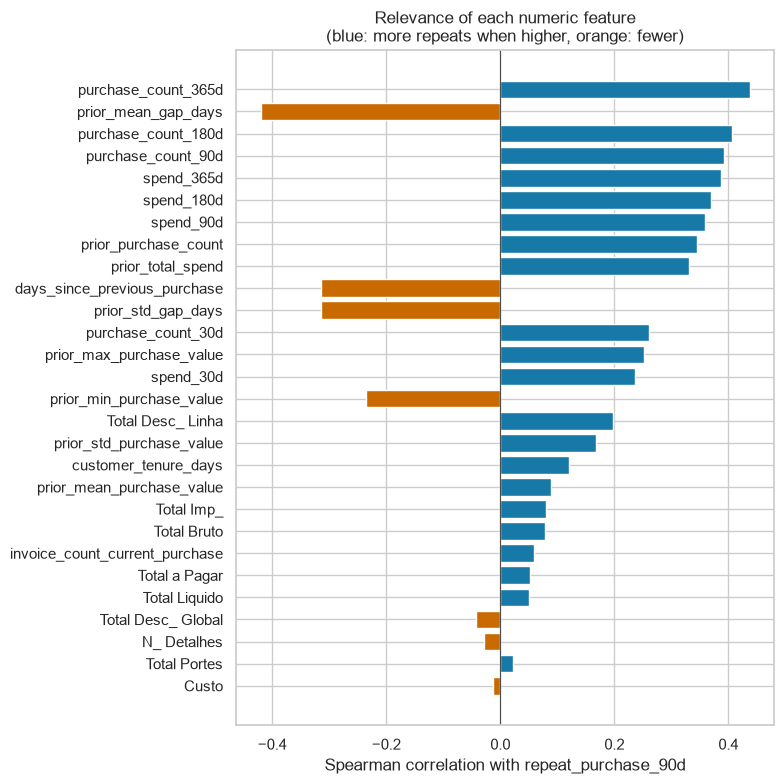

In [33]:
fig, ax = plt.subplots(figsize=(8, 8))
values = relevance["Spearman rho"]
ax.barh(values.index[::-1], values.values[::-1],
        color=[PLOT_BLUE if v > 0 else PLOT_ORANGE for v in values.values[::-1]])
ax.axvline(0, color="0.3", lw=0.8)
ax.set(xlabel="Spearman correlation with repeat_purchase_90d",
       title="Relevance of each numeric feature\n(blue: more repeats when higher, orange: fewer)")
plt.tight_layout()
plt.show()

**Reading the ranking**

* **Recency and recent frequency dominate.** The strongest signals are the rolling-window counts and spends
  (`purchase_count_90d`, `purchase_count_180d`, `spend_90d`, ...), positively, and `days_since_previous_purchase` and
  `prior_mean_gap_days`, negatively. Customers who buy *often* and *recently* come back: the classic RFM logic
  (Recency, Frequency, Monetary).
* **The size of the current invoice matters much less** than the customer's rhythm. The invoice amounts have small
  correlations.
* `customer_tenure_days` is weakly related: being an old customer is not the same as being an active one.
* With n ≈ 6,500, even tiny correlations have small p-values. Statistical significance is not the same as usefulness
  (Data Mining, S3), so we read the **effect size**, not the p-value.

### 9.2 The recency effect in detail

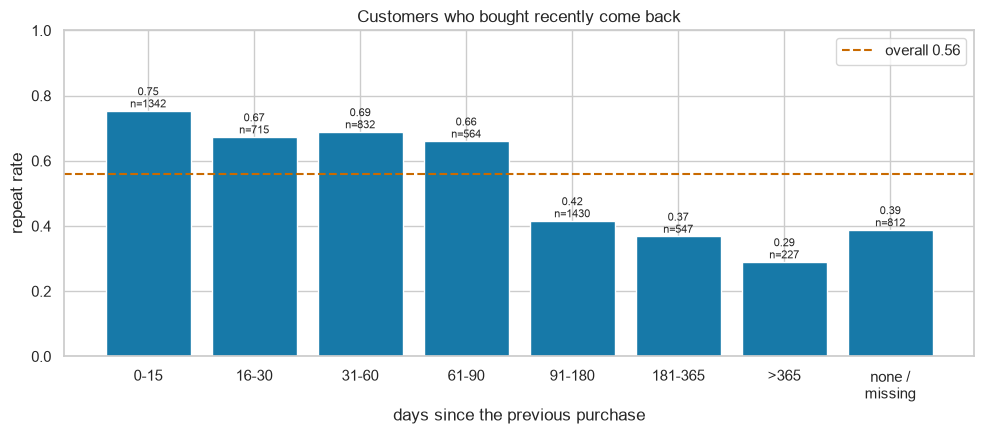

In [34]:
bins = [0, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15", "16-30", "31-60", "61-90", "91-180", "181-365", ">365"]
recency = pd.cut(df_eda["days_since_previous_purchase"], bins=bins, labels=labels, include_lowest=True)
recency = recency.cat.add_categories("none /\nmissing").fillna("none /\nmissing")
by_recency = df_eda.groupby(recency, observed=True)[target_col].agg(["mean", "size"]).rename(
    columns={"mean": "repeat rate", "size": "rows"})

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(by_recency.index.astype(str), by_recency["repeat rate"], color=PLOT_BLUE)
ax.axhline(df_eda[target_col].mean(), color=PLOT_ORANGE, ls="--", label=f"overall {df_eda[target_col].mean():.2f}")
for i, (rate, n) in enumerate(zip(by_recency["repeat rate"], by_recency["rows"])):
    ax.text(i, rate + 0.01, f"{rate:.2f}\nn={n}", ha="center", fontsize=8)
ax.set(ylim=(0, 1), xlabel="days since the previous purchase", ylabel="repeat rate",
       title="Customers who bought recently come back")
ax.legend()
plt.tight_layout()
plt.show()

In [35]:
# Frequency: repeat rate by number of purchases in the previous 90 days.
freq = df_eda["purchase_count_90d"].clip(upper=6).astype("Int64").astype(str).replace({"6": "6+"})
df_eda.groupby(freq)[target_col].agg(["mean", "size"]).rename(columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
purchase_count_90d,,
0,0.379,2889
1,0.568,1714
2,0.712,787
3,0.832,328
4,0.879,149
5,0.940,100
6+,0.986,502


* There is a **clear break around 90 days**: customers whose previous purchase was less than 90 days ago come back in
  ≈66–75% of the cases; beyond 90 days the rate falls to ≈40%, and to ≈30% after a year. The relationship is
  monotonic but **not linear**, which supports binning or a `log1p` transform for a linear model.
* **First-time buyers** (no previous purchase) come back in only **33%** of the cases, the lowest rate of all groups.
  This is another reason to keep an explicit `is_first_purchase` flag rather than filling their gaps with a number.
* Frequency tells the same story even more sharply: with no purchase in the previous 90 days the rate is 38%, with one
  57%, with three 83%, and with six or more 99%.

**Feature engineering idea for Part 2:** the absolute recency means different things for different customers (30 days
is long for a weekly buyer and short for a yearly buyer). A ratio such as
`days_since_previous_purchase / prior_mean_gap_days` ("is the customer early or late compared with their own rhythm?")
puts every customer on the same scale.

In [36]:
# Quick check of that idea (exploration only): repeat rate by quintile of the rhythm ratio.
rhythm = df_eda["days_since_previous_purchase"] / df_eda["prior_mean_gap_days"].replace(0, np.nan)
df_eda.groupby(pd.qcut(rhythm, 5), observed=True)[target_col].agg(["mean", "size"]).rename(
    columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
"(0.00017, 0.257]",0.595,1007
"(0.257, 0.626]",0.683,1006
"(0.626, 1.045]",0.594,1006
"(1.045, 1.747]",0.570,1006
"(1.747, 478.667]",0.553,1006


The ratio has signal, but it is not monotonic: customers who are at about half of their usual gap come back most,
while customers who are far beyond their usual gap come back least. It is a candidate feature that feature
selection will have to judge, not a guaranteed winner.

### 9.3 Categorical variables vs the target

For two categorical variables the course measure is the **chi-square test** with **Cramér's V** as the effect size.
Rare levels make the chi-square approximation unreliable (expected counts < 5), so we report the smallest expected count too.

In [37]:
cat_rows = []
for col in categorical_cols:
    x = df_eda[col].fillna("<missing>")
    table = pd.crosstab(x, df_eda[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    cat_rows.append({"feature": col, "levels": table.shape[0], "chi2": chi2, "p-value": p_value,
                     "Cramer's V": v, "min expected count": expected.min()})
pd.DataFrame(cat_rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(4)

,levels,chi2,p-value,Cramer's V,min expected count
feature,,,,,
transport_method,81,527.2252,0.0000,0.2855,0.4403
payment_type,10,354.3527,0.0000,0.2340,1.7610
salesperson,10,260.7604,0.0000,0.2008,1.3208
commercial_zone,5,26.2955,0.0000,0.0638,0.4403
warehouse,3,10.1673,0.0062,0.0396,9.2453
document_series,3,0.0553,0.9727,0.0029,804.7834


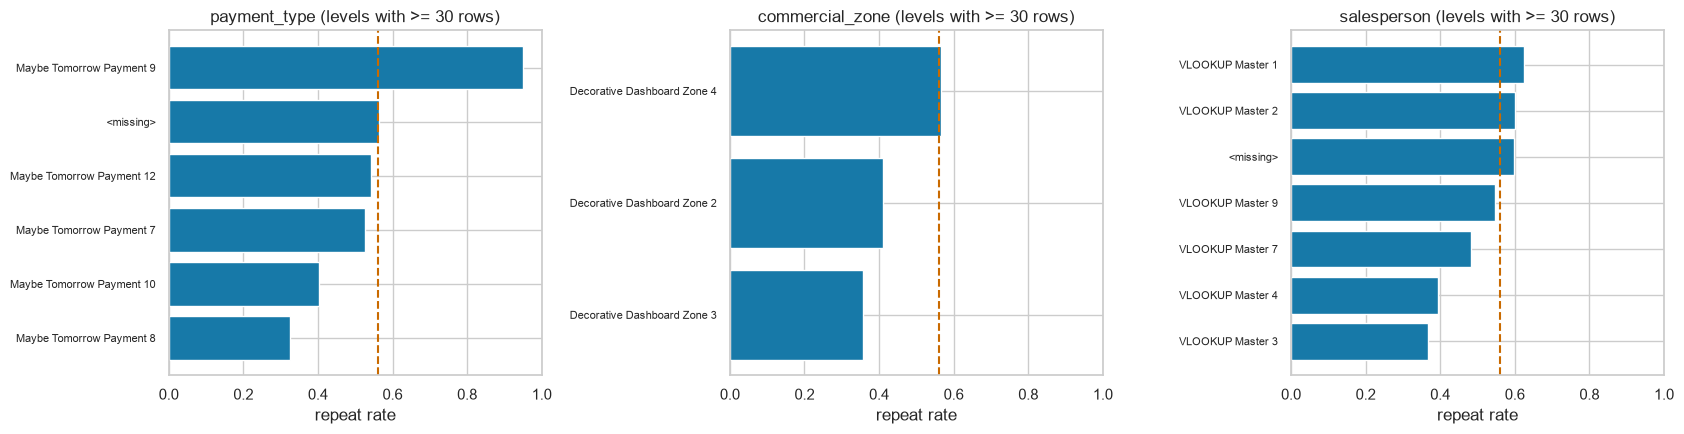

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["payment_type", "commercial_zone", "salesperson"]):
    stats_by_level = df_eda.groupby(df_eda[col].fillna("<missing>"))[target_col].agg(["mean", "size"])
    stats_by_level = stats_by_level[stats_by_level["size"] >= 30].sort_values("mean")
    ax.barh(stats_by_level.index, stats_by_level["mean"], color=PLOT_BLUE)
    ax.axvline(df_eda[target_col].mean(), color=PLOT_ORANGE, ls="--")
    ax.set(xlim=(0, 1), title=f"{col} (levels with >= 30 rows)", xlabel="repeat rate")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `transport_method`, `payment_type` and `salesperson` show a moderate association (Cramér's V 0.20–0.29). Some payment types
  have repeat rates far above or below the average, which is plausible: payment terms reflect the type of commercial
  relationship (regular account customers vs one-off buyers).
* `transport_method` has a high V partly *because* it has 80 levels: many tiny levels with extreme rates inflate the
  statistic (and their expected counts are far below 5). Grouping rare levels into `"Other"` is what makes this
  variable usable without overfitting.
* `commercial_zone` and `warehouse` are weakly related, and `document_series` is unrelated (V ≈ 0, p = 0.97).

# <font color='#E8800A'>10 · Redundancy between predictors</font> <a class="anchor" id="redundancy"></a>
[Back to TOC](#toc)

A relevance ranking compares each column with the target only. Two columns can both be relevant and still say the
same thing. We use the **Spearman** correlation (robust to the skewed tails) between all numeric columns, and list
the pairs above 0.90.

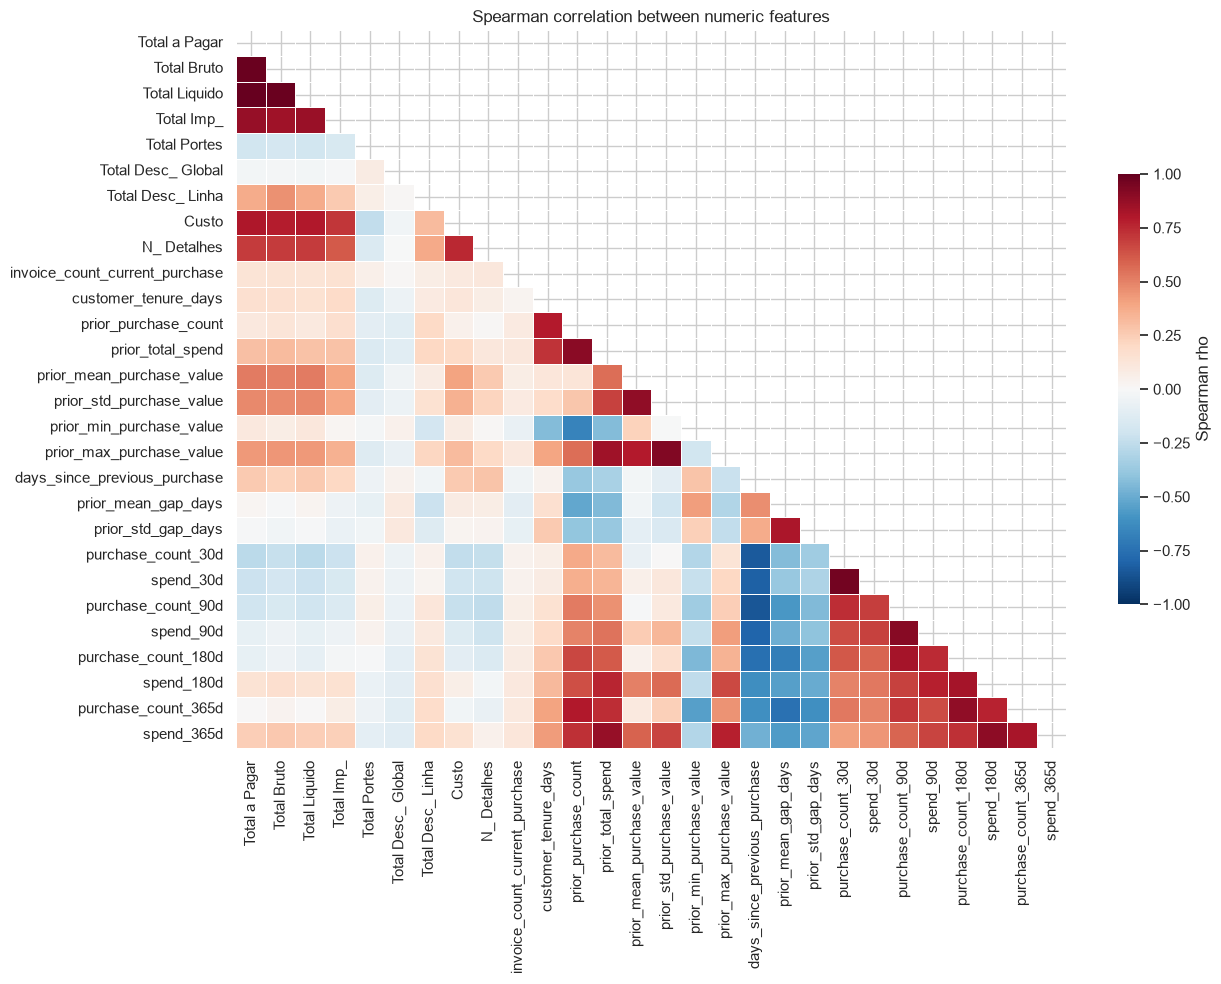

In [39]:
corr = df_eda[numeric_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"shrink": 0.6, "label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation between numeric features")
plt.tight_layout()
plt.show()

In [40]:
pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
         .rename("Spearman rho").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs = pairs.reindex(pairs["Spearman rho"].abs().sort_values(ascending=False).index)
pairs[pairs["Spearman rho"].abs() >= 0.90].round(3).reset_index(drop=True)

,feature A,feature B,Spearman rho
0,Total Liquido,Total a Pagar,1.000
1,Total Liquido,Total Bruto,0.991
2,Total Bruto,Total a Pagar,0.991
3,spend_30d,purchase_count_30d,0.965
4,prior_max_purchase_value,prior_std_purchase_value,0.923
5,spend_90d,purchase_count_90d,0.909
6,prior_total_spend,prior_purchase_count,0.903


Seven pairs exceed 0.90:

* `Total a Pagar`, `Total Bruto` and `Total Liquido` (ρ 0.99–1.00). Section 6.5 showed why: they are linked by
  accounting identities. One of them carries all the information.
* Short-window counts and spends: `purchase_count_30d` ↔ `spend_30d` (0.97), `purchase_count_90d` ↔ `spend_90d` (0.91).
* `prior_purchase_count` ↔ `prior_total_spend` (0.90) and `prior_max_purchase_value` ↔ `prior_std_purchase_value` (0.92).
* Below the 0.90 line the heatmap still shows large blocks (the nested windows among themselves, the invoice amounts
  with `Total Imp_` and `Custo`), so the redundancy is broader than these seven pairs.
* Redundancy hurts a **linear** model the most (unstable coefficients under multicollinearity). → **Planned for Part 3:**
  a redundancy filter (|ρ| > 0.90: keep the more relevant of each pair), followed by the wrapper and embedded methods.

# <font color='#E8800A'>11 · The customer table `clientes.csv`</font> <a class="anchor" id="clientes"></a>
[Back to TOC](#toc)

The brief asks us to *decide whether and how* to integrate this table through `customer_id`. We first check its quality,
then whether it adds anything that is not already in the transactions.

In [41]:
quality = pd.DataFrame({
    "% missing": (100 * df_clientes.isna().mean()).round(1),
    "distinct values": df_clientes.nunique(),
    "distinct / rows": (df_clientes.nunique() / len(df_clientes)).round(3),
})
print(f"{len(df_clientes):,} customers, customer_id unique: {df_clientes['customer_id'].is_unique}")
print(f"train customers found in clientes: {df['customer_id'].isin(df_clientes['customer_id']).mean():.0%}"
      f" | df_test customers found: {df_test['customer_id'].isin(df_clientes['customer_id']).mean():.0%}")
quality

1,143 customers, customer_id unique: True
train customers found in clientes: 100% | df_test customers found: 100%


,% missing,distinct values,distinct / rows
customer_id,0.0,1143,1.000
country_or_region,0.0,11,0.010
commercial_region,10.0,37,0.032
island,50.6,10,0.009
municipality,13.9,183,0.160
city,47.8,417,0.365
postal_area,6.2,271,0.237
postal_code,14.9,828,0.724
street,52.3,511,0.447
address,0.5,1120,0.980


* `customer_id` is a clean key: unique in `clientes.csv`, and **every** customer of train and test is found.
* `customer_type` is **100% empty** → useless.
* `company_name`, `address`, `street`, `postal_code`, `city` are (almost) unique per customer: they identify the customer
  rather than describe them, with the same risk as using `customer_id` itself (memorising customers). Several are
  also half empty.
* The usable candidates are the coarse geography (`country_or_region` 11 levels, `commercial_region` 37,
  `island` 10, `municipality` 183) and `customer_since_year`.

In [42]:
# Attach the candidate columns to each purchase, then measure their association with the target.
candidates = ["country_or_region", "commercial_region", "island", "municipality", "customer_since_year"]
joined = df_eda.join(df_clientes.set_index(group_col)[candidates], on=group_col)

rows = []
for col in candidates:
    x = joined[col].astype("string").fillna("<missing>")
    table = pd.crosstab(x, joined[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    rows.append({"feature": col, "levels": table.shape[0],
                 "Cramer's V": np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))),
                 "min expected count": expected.min()})
pd.DataFrame(rows).set_index("feature").round(3)

,levels,Cramer's V,min expected count
feature,,,
country_or_region,7,0.066,0.440
commercial_region,33,0.264,0.440
island,11,0.148,4.403
municipality,151,0.365,0.440
customer_since_year,10,0.196,11.447


In [43]:
# Is customer_since_year new information, or the same as customer_tenure_days?
purchase_year = pd.to_datetime(joined["purchase_date"]).dt.year
years_as_customer = purchase_year - joined["customer_since_year"]
rho, _ = stats.spearmanr(years_as_customer, joined["customer_tenure_days"], nan_policy="omit")
print(f"Spearman(purchase year - customer_since_year, customer_tenure_days) = {rho:.3f}")
print(f"purchases made BEFORE the customer_since_year: {(years_as_customer < 0).mean():.1%}")

Spearman(purchase year - customer_since_year, customer_tenure_days) = 0.917
purchases made BEFORE the customer_since_year: 0.0%


**Decision on `clientes.csv` (to be implemented in Part 2)**

* **Integrate, but only the coarse geography**: `country_or_region`, `commercial_region` and `island` (missing →
  `"Missing"`, rare levels → `"Other"`). They are clean descriptions of *where* the customer is, which could matter for
  logistics and sales coverage. Their association with the target ranges from weak (`country_or_region`, V = 0.07) to
  moderate (`commercial_region`, V = 0.26). Part of the latter comes from its 33 levels, many of them tiny, the same
  inflation we saw with `transport_method`. The feature selection judges them like every other feature: if they add
  nothing, they are dropped there, and the PDF will say so.
* **Do not use** `customer_type` (empty), `company_name`, `address`, `street`, `postal_code`, `city` (identifiers in
  disguise) or `municipality` (183 levels for 610 customers: too fine to generalise; its high V = 0.37 is mostly memorisation of
  the few customers in each municipality).
* **Do not use** `customer_since_year`: "years since the customer joined" correlates at ρ = 0.92 with
  `customer_tenure_days`, which is measured to the day and already in the transactions. The two tables are
  consistent (no purchase happens before the customer's joining year), so the year adds nothing new.

High-cardinality geography deserves the same suspicion as identifiers: with only 610 customers, a municipality with
two customers is essentially a customer ID.

# <font color='#E8800A'>12 · Identifiers and the noise column</font> <a class="anchor" id="identifiers"></a>
[Back to TOC](#toc)

The brief asks to treat identifier-like variables *critically rather than accepting them automatically*. We test
`ID`, `customer_id` and `random_noise` against the target and against the time.

In [44]:
id_frame = df.reset_index()
checks = pd.DataFrame({
    "Spearman with target": [stats.spearmanr(id_frame[c], id_frame[target_col])[0]
                             for c in ["ID", group_col, "random_noise"]],
    "Spearman with purchase date": [stats.spearmanr(id_frame[c], pd.to_datetime(id_frame["purchase_date"]).astype("int64"))[0]
                                    for c in ["ID", group_col, "random_noise"]],
}, index=["ID", group_col, "random_noise"])
checks.round(3)

,Spearman with target,Spearman with purchase date
ID,0.012,0.011
customer_id,-0.116,-0.022
random_noise,-0.008,0.018


In [45]:
# Why would customer_id correlate with the target at all? Look at the customers with the most rows.
top = per_customer.sort_values(ascending=False).head(5)
summary = df[df[group_col].isin(top.index)].groupby(group_col)[target_col].agg(["size", "mean"])
summary.rename(columns={"size": "purchases", "mean": "repeat rate"}).sort_values("purchases", ascending=False).round(3)

,purchases,repeat rate
customer_id,,
103940,276,0.993
258332,200,1.000
755628,107,0.944
151492,88,0.852
519184,88,0.875


* **`ID`** is a row number: no relation with the target or with time. It stays as the index (needed for the
  submission) and is never a feature.
* **`customer_id`** shows a small correlation with the target (ρ ≈ −0.1). That is a **spurious relationship**: the
  number is an arbitrary code, and the correlation appears only because a few very active customers (hundreds of
  purchases, repeat rates close to 1) happen to have particular ID values. A model could "learn" that numeric range
  and memorise those customers, which says nothing about a new purchase pattern. It is excluded as a feature
  (Data Mining, S3: features should have a *meaningful and defensible* relationship with the phenomenon). It is still
  useful as a **key** for the join with `clientes.csv` and for any customer-aware validation check.
* **`random_noise`** has no relation with anything (ρ ≈ 0 with the target and with time). Its name says what it is.
  We will **not** delete it by hand: we keep it as a *control* in feature selection (Part 3). A sound selection
  strategy should discard it on its own, and if a method keeps it, that method is overfitting.

# <font color='#E8800A'>13 · Key findings and decisions carried to Part 2</font> <a class="anchor" id="findings"></a>
[Back to TOC](#toc)

**What we learned**

1. **The target is 56% positive and the metric is F1 of class 1**, so "everybody repeats" already scores F1 ≈ 0.72.
   Every result must beat that floor, and the classification threshold must be tuned.
2. **The data is mostly clean but has deliberate traps**: 65 empty rows, impossible values in 94 rows (1e9 codes and
   negatives), structural missingness in the history columns, test categories never seen in train (21% of test rows
   for `commercial_zone`), and a `random_noise` column.
3. **The test set is the future** (May 2025 – Oct 2026, after all training data), with mostly **known customers**.
   Cumulative features (tenure, total history) drift upward over time; the purchase year cannot be used.
4. **Behaviour beats size**: recency and frequency (RFM) are by far the strongest signals; invoice amounts are weak.
   There is a sharp break in the repeat rate at ≈90 days since the previous purchase.
5. **Strong redundancy**: the three invoice totals, short-window count/spend pairs and two history pairs are
   near-duplicates (ρ > 0.9).
6. **Outliers are customers, not errors**: the IQR rule would flag 7–10% of the rows, mostly loyal high-value customers
   whose repeat rate is 84–97%.
7. **`clientes.csv`** is clean as a key; only its coarse geography is worth testing.

**Decisions carried to Part 2 (pre-processing) and beyond**

| Step | Decision | Fitted on |
|---|---|---|
| Rows | drop the 65 empty rows from training | rule |
| Placeholders | 1e9 and negative values → `NaN` (train and test alike) | rule |
| Missing history | `is_first_purchase` flag + missing indicators + median imputation | training rows |
| Missing categories | `"Missing"` level | rule |
| Rare / unseen levels | grouped into `"Other"` via `min_frequency` / `handle_unknown` | training rows |
| Long tails | `log1p` on money, count and gap columns; no outlier deletion | rule |
| Scaling | `StandardScaler` for the linear model | training rows |
| `clientes.csv` | join `country_or_region`, `commercial_region`, `island` | — |
| New features | recency/rhythm ratio, margin and discount ratios, spend acceleration; **no** purchase year | rule |
| Identifiers | `ID` = index; `customer_id` = join key only; `random_noise` kept as a selection control | — |
| Validation (Part 4) | temporal hold-out as the main design, compared with stratified and grouped k-fold | — |
| Metric (Part 4) | F1 of class 1 vs the all-ones floor, with threshold tuning; precision, recall and AUC as support | — |